<center><h1>Zheng_Yifei_HW4</h1></center>
<br>
<br>

Name: Yifei Zheng
<br>
Github Username: yyl-ff
<br>
USC ID: 8538054131

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [3]:
import os
import glob
import numpy as np
import pandas as pd

from scipy.stats import bootstrap
from sklearn.utils import resample

Get the AReM Data Set

In [11]:
data_path = "AReM"

activity_folders = sorted([
    name for name in os.listdir(data_path)
    if os.path.isdir(os.path.join(data_path, name))
])

print("Dataset folder:", data_path)
print("Activity folders:", activity_folders)

Dataset folder: AReM
Activity folders: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


### (b) Splitting Data

In [13]:
train_files = []
test_files = []

for activity in activity_folders:
    folder_path = os.path.join(data_path, activity)
    csv_files = glob.glob(os.path.join(folder_path, "dataset*.csv"))

    for file_path in csv_files:
        file_name = os.path.basename(file_path)
        dataset_number = int(file_name.replace("dataset", "").replace(".csv", ""))

        if activity in ["bending1", "bending2"]:
            if dataset_number in [1, 2]:
                test_files.append((activity, file_path))
            else:
                train_files.append((activity, file_path))
        else:
            if dataset_number in [1, 2, 3]:
                test_files.append((activity, file_path))
            else:
                train_files.append((activity, file_path))

print("Number of training instances:", len(train_files))
print("Number of testing instances:", len(test_files))
print("Total number of instances:", len(train_files) + len(test_files))

Number of training instances: 69
Number of testing instances: 19
Total number of instances: 88


### (c) Feature Extraction

In [15]:
def read_time_series(file_path):
    # bending2/dataset4.csv uses spaces instead of commas
    if file_path.endswith(os.path.join("bending2", "dataset4.csv")):
        data = pd.read_csv(
            file_path,
            skiprows=5,
            sep=r"\s+",
            header=None,
            usecols=range(7),
            engine="python"
        )
    else:
        data = pd.read_csv(
            file_path,
            skiprows=5,
            header=None,
            usecols=range(7),
            engine="python"
        )

    # Remove the first column because it represents time
    time_series = data.iloc[:, 1:7].apply(
        pd.to_numeric,
        errors="coerce"
    )

    return time_series.dropna()


def extract_features(file_list, data_type):
    rows = []

    for activity, file_path in file_list:
        time_series = read_time_series(file_path)

        row = {
            "Activity": activity,
            "File": os.path.basename(file_path),
            "Set": data_type
        }

        for i in range(6):
            values = time_series.iloc[:, i]

            row[f"min{i + 1}"] = values.min()
            row[f"max{i + 1}"] = values.max()
            row[f"mean{i + 1}"] = values.mean()
            row[f"median{i + 1}"] = values.median()
            row[f"std{i + 1}"] = values.std()
            row[f"1st_quart{i + 1}"] = values.quantile(0.25)
            row[f"3rd_quart{i + 1}"] = values.quantile(0.75)

        rows.append(row)

    return pd.DataFrame(rows)


# Extract features from the training and test instances
train_features = extract_features(train_files, "Train")
test_features = extract_features(test_files, "Test")

# Combine all 88 instances
feature_data = pd.concat(
    [train_features, test_features],
    ignore_index=True
)

# Add the instance number
feature_data.insert(
    0,
    "Instance",
    range(1, len(feature_data) + 1)
)

# Identify the 42 extracted feature columns
feature_columns = [
    column for column in feature_data.columns
    if column not in ["Instance", "Activity", "File", "Set"]
]

print("Number of instances:", feature_data.shape[0])
print("Number of extracted features:", len(feature_columns))
print(
    "Total missing values:",
    feature_data[feature_columns].isna().sum().sum()
)

display(
    feature_data.head().style.hide(axis="index")
)

Number of instances: 88
Number of extracted features: 42
Total missing values: 0


Instance,Activity,File,Set,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
1,bending1,dataset7.csv,Train,36.250000,48.000000,43.969125,44.500000,1.618364,43.310000,44.670000,0.000000,1.500000,0.413125,0.470000,0.263111,0.430000,0.500000,1.500000,26.330000,15.868021,16.250000,3.742420,14.250000,18.000000,0.000000,5.170000,0.666354,0.470000,0.788985,0.000000,0.940000,11.330000,30.750000,22.103750,21.670000,3.318301,20.500000,23.750000,0.000000,2.960000,0.555312,0.490000,0.487826,0.000000,0.830000
2,bending1,dataset6.csv,Train,37.000000,48.000000,43.454958,43.250000,1.386098,42.500000,45.000000,0.000000,1.580000,0.378083,0.470000,0.315566,0.000000,0.500000,5.750000,27.000000,15.793333,15.000000,3.847638,13.000000,18.270000,0.000000,10.030000,0.849354,0.500000,0.995761,0.430000,1.120000,8.000000,33.500000,23.034792,23.500000,2.488862,22.250000,24.000000,0.000000,5.260000,0.679646,0.500000,0.622534,0.430000,0.870000
3,bending1,dataset4.csv,Train,33.000000,47.750000,42.179812,43.500000,3.670666,39.150000,45.000000,0.000000,3.000000,0.696042,0.500000,0.630860,0.000000,1.120000,8.500000,30.000000,22.183625,23.000000,3.810469,20.500000,24.372500,0.000000,5.150000,0.989917,0.830000,0.953730,0.430000,1.300000,20.000000,38.670000,33.493917,35.000000,3.849448,30.457500,36.330000,0.000000,2.180000,0.613521,0.500000,0.524317,0.000000,1.000000
4,bending1,dataset5.csv,Train,33.000000,45.750000,41.678063,41.750000,2.243490,41.330000,42.750000,0.000000,2.830000,0.535979,0.500000,0.405469,0.430000,0.710000,3.000000,28.250000,19.006563,19.125000,4.087107,16.500000,22.062500,0.000000,6.420000,0.841875,0.500000,0.928801,0.430000,1.120000,23.670000,37.500000,29.857083,30.000000,2.411026,28.457500,31.250000,0.000000,1.790000,0.383292,0.430000,0.389164,0.000000,0.500000
5,bending1,dataset3.csv,Train,35.000000,47.400000,43.954500,44.330000,1.558835,43.000000,45.000000,0.000000,1.700000,0.426250,0.470000,0.338690,0.000000,0.500000,6.500000,29.750000,22.122354,23.000000,3.030943,19.750000,24.000000,0.000000,4.440000,0.497312,0.430000,0.550657,0.000000,0.830000,29.000000,38.500000,35.588458,36.000000,1.999604,35.362500,36.500000,0.000000,1.790000,0.493292,0.430000,0.513506,0.000000,0.940000


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

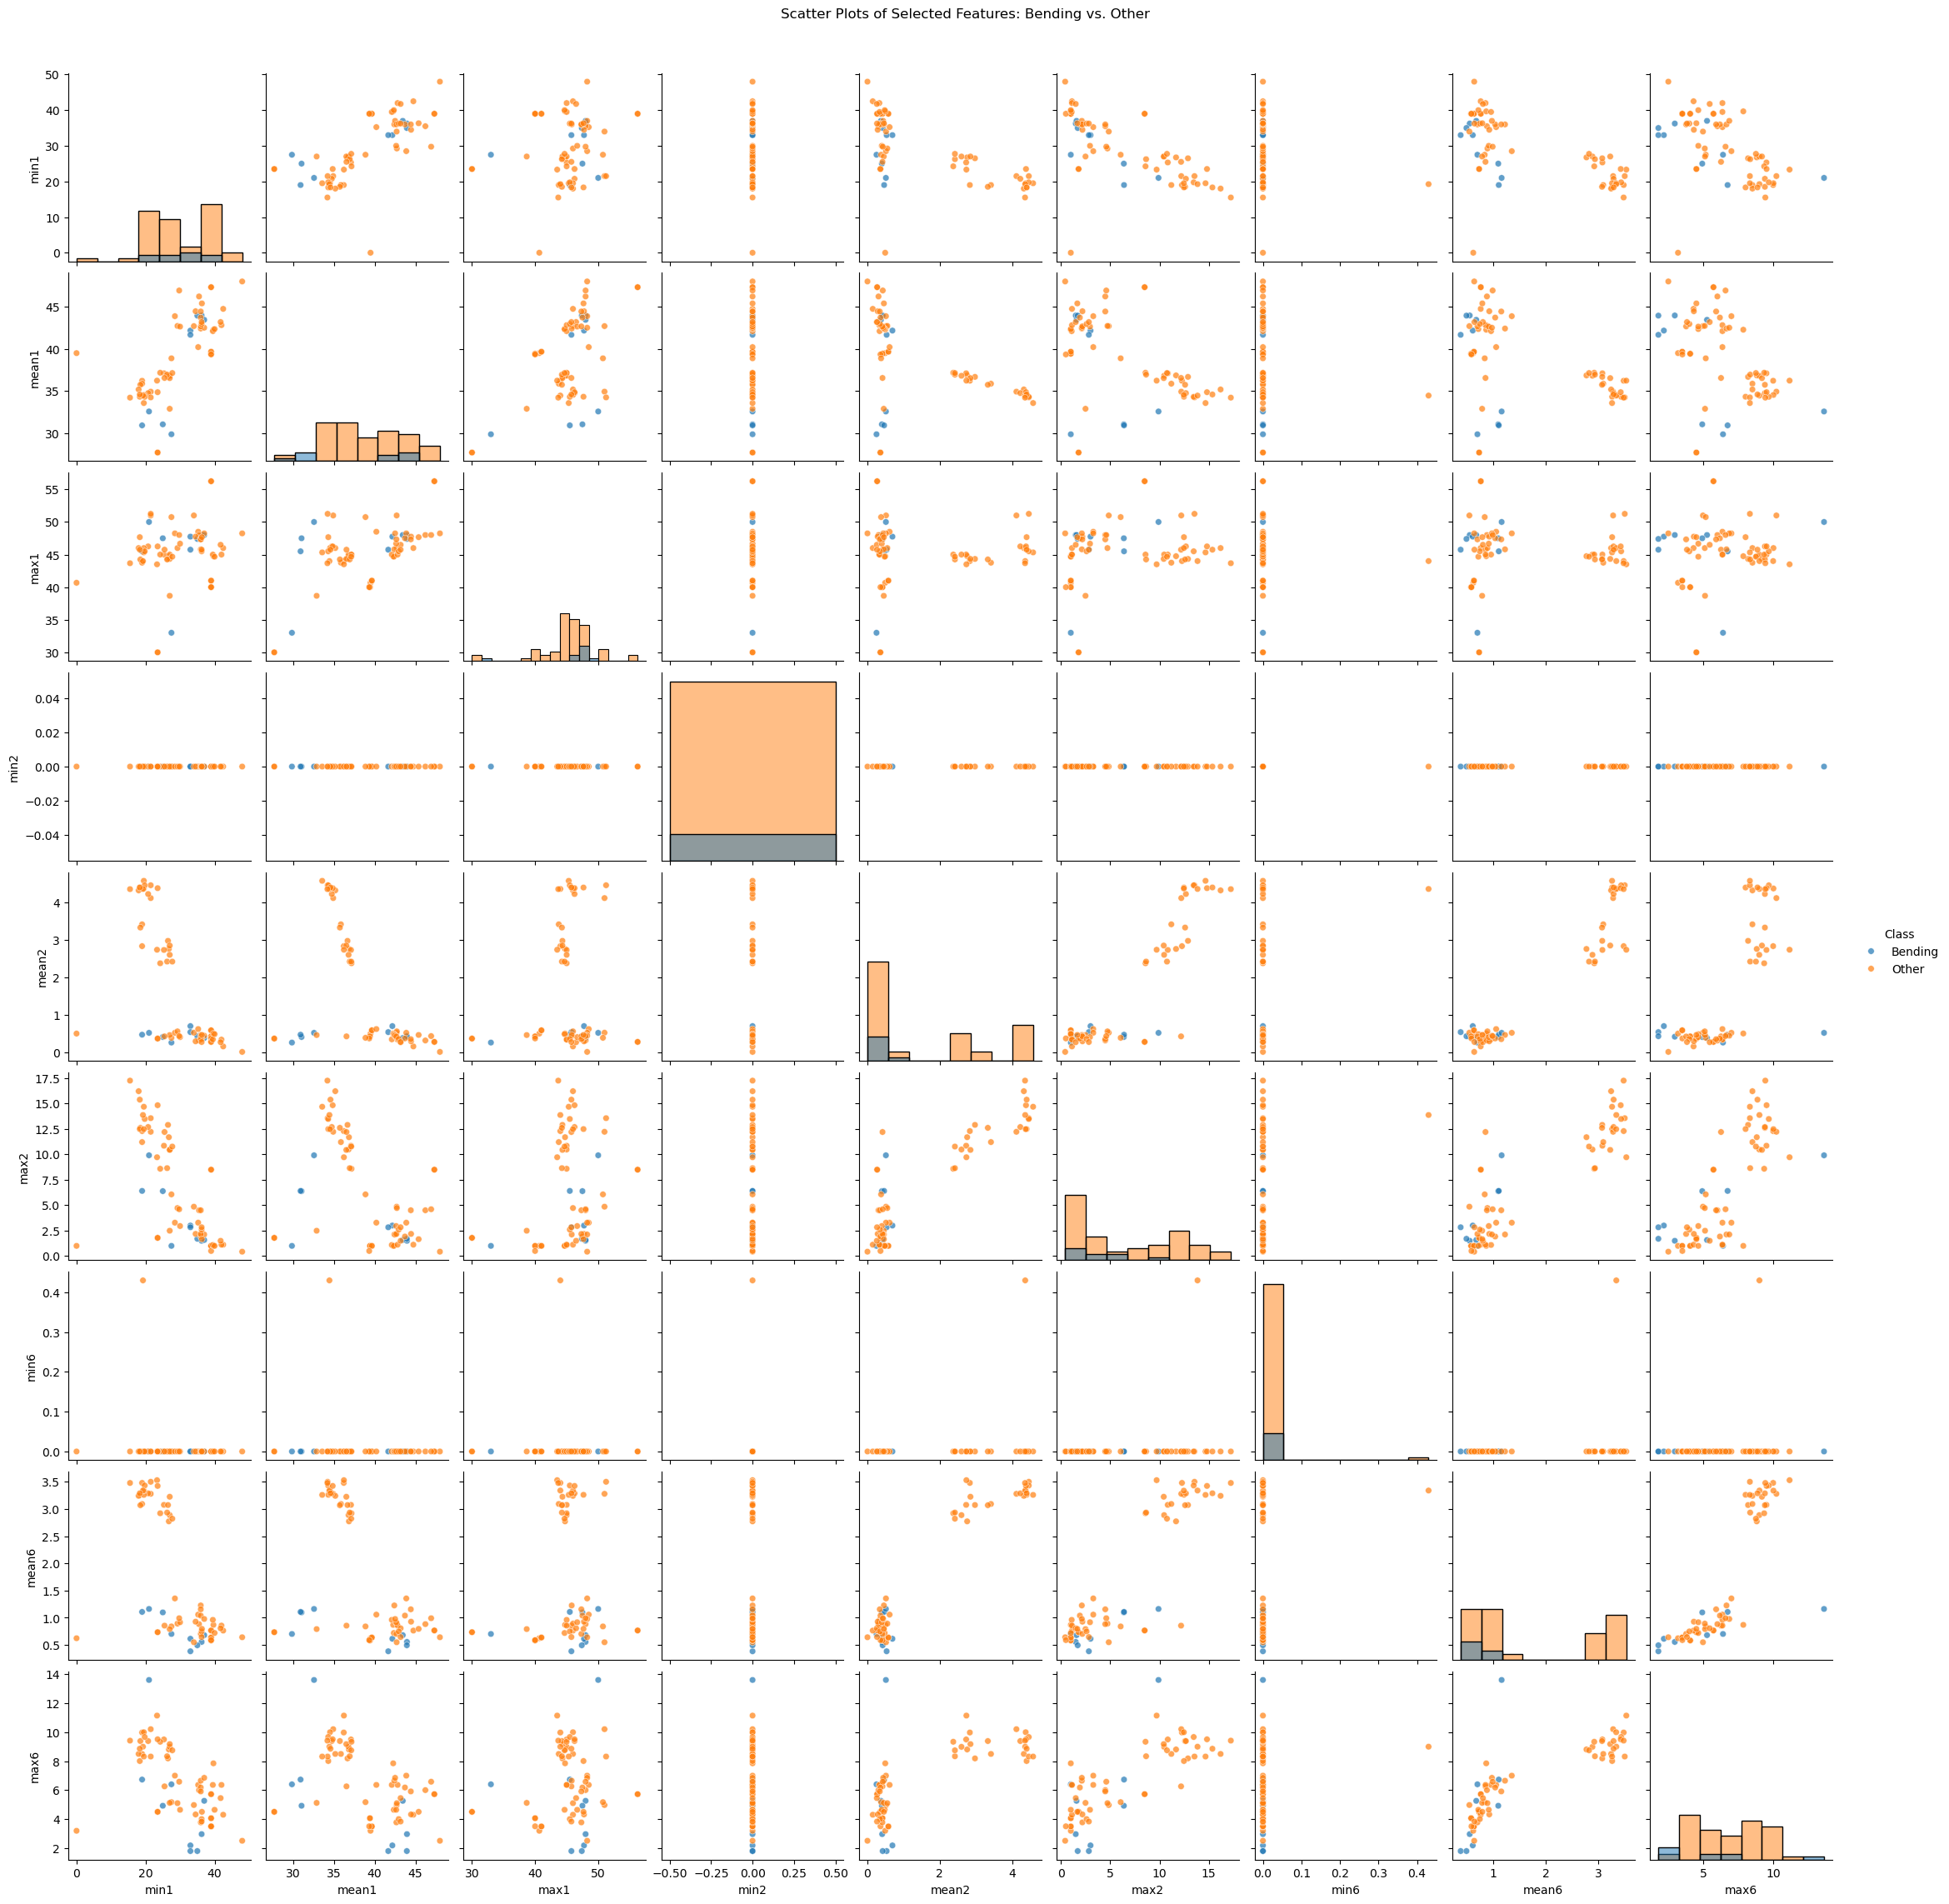

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use only the training data
plot_data = train_features.copy()

# Create the binary class label
plot_data["Class"] = np.where(
    plot_data["Activity"].isin(["bending1", "bending2"]),
    "Bending",
    "Other"
)

# Use min, mean, and max from time series 1, 2, and 6
selected_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

sns.pairplot(
    plot_data,
    vars=selected_features,
    hue="Class",
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 30}
)

plt.suptitle(
    "Scatter Plots of Selected Features: Bending vs. Other",
    y=1.02
)

plt.show()

#### ii. Splitted Plots

Number of training instances: 69


Activity,Class,min1_part1,mean1_part1,max1_part1,min2_part1,mean2_part1,max2_part1,min6_part1,mean6_part1,max6_part1,min1_part2,mean1_part2,max1_part2,min2_part2,mean2_part2,max2_part2,min6_part2,mean6_part2,max6_part2
bending1,Bending,36.670000,43.486208,45.000000,0.000000,0.378667,1.300000,0.000000,0.524875,2.280000,36.250000,44.452042,48.000000,0.000000,0.447583,1.500000,0.000000,0.585750,2.960000
bending1,Bending,39.000000,44.117042,48.000000,0.000000,0.250042,1.300000,0.000000,0.815417,5.260000,37.000000,42.792875,46.500000,0.000000,0.506125,1.580000,0.000000,0.543875,4.060000
bending1,Bending,33.750000,43.278875,47.750000,0.000000,0.673292,3.000000,0.000000,0.640958,1.530000,33.000000,41.080750,46.000000,0.000000,0.718792,2.860000,0.000000,0.586083,2.180000
bending1,Bending,33.000000,41.621208,45.750000,0.000000,0.623083,2.830000,0.000000,0.419083,1.790000,39.250000,41.734917,43.670000,0.000000,0.448875,1.120000,0.000000,0.347500,1.500000
bending1,Bending,36.500000,44.057167,46.500000,0.000000,0.381042,1.500000,0.000000,0.598250,1.790000,35.000000,43.851833,47.400000,0.000000,0.471458,1.700000,0.000000,0.388333,1.500000


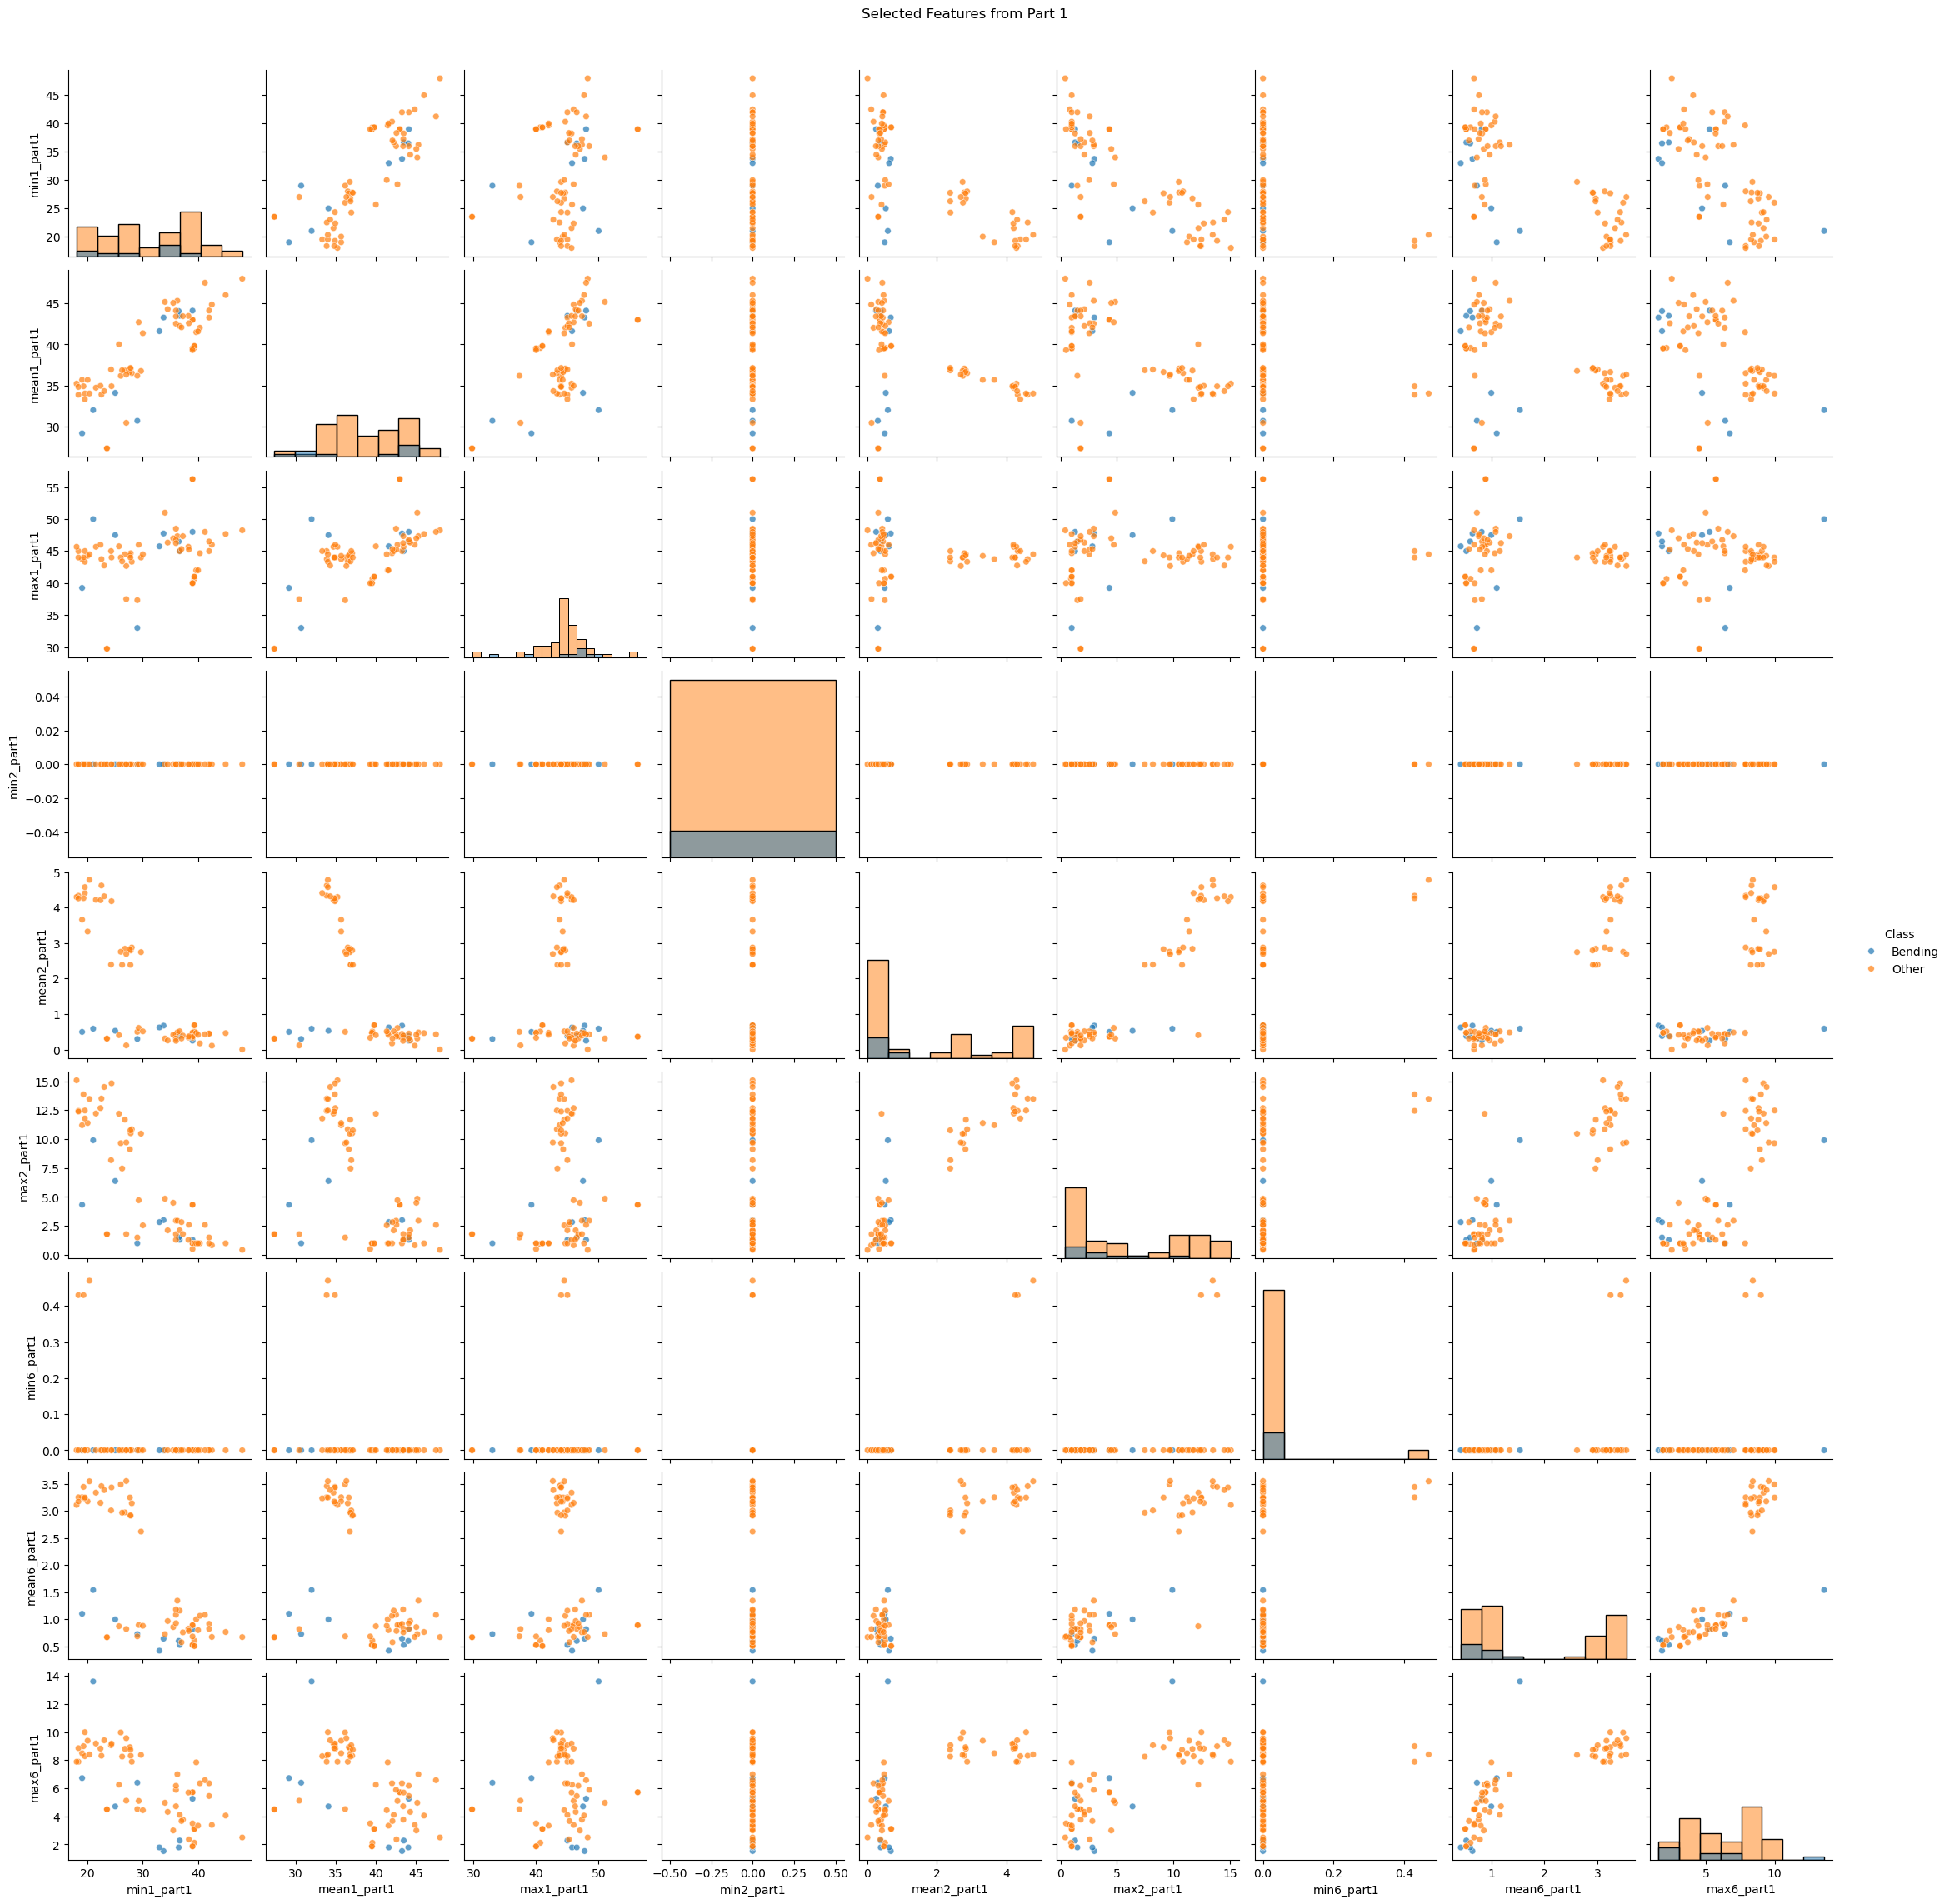

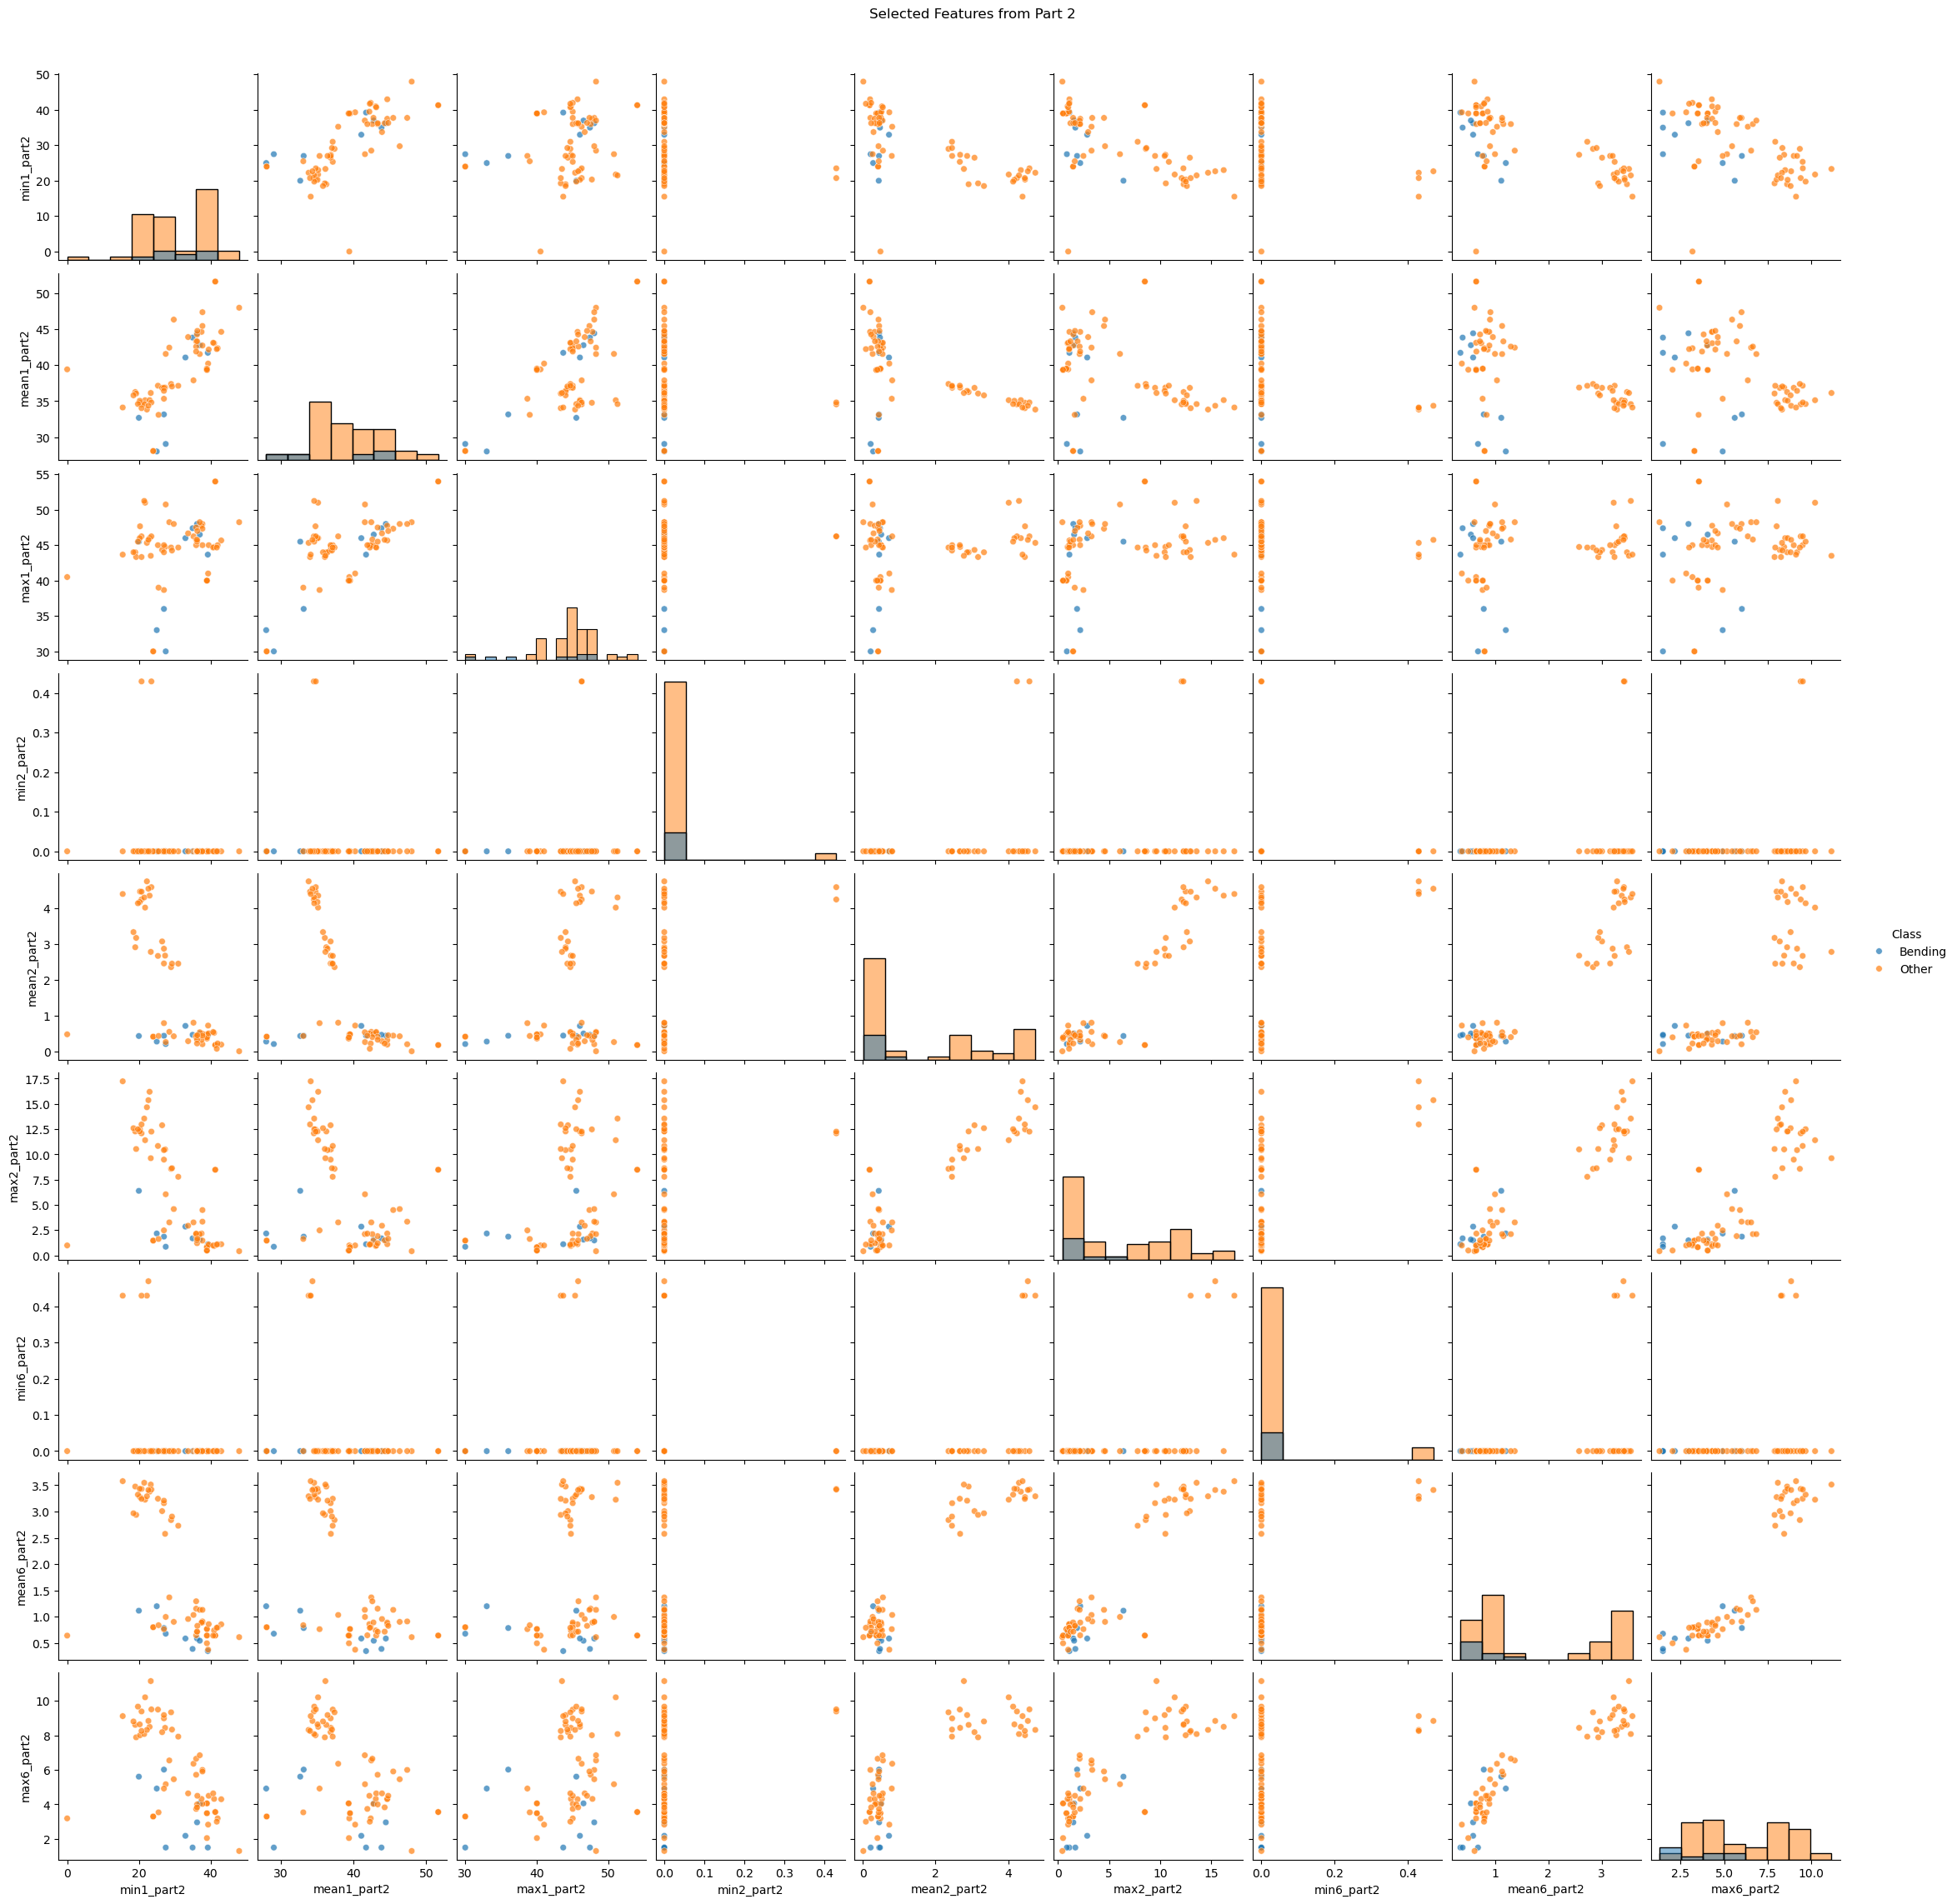

In [19]:
split_rows = []

for activity, file_path in train_files:
    time_series = read_time_series(file_path)

    # Split the 480 observations into two parts
    index_parts = np.array_split(
        np.arange(len(time_series)),
        2
    )

    row = {
        "Activity": activity,
        "Class": (
            "Bending"
            if activity in ["bending1", "bending2"]
            else "Other"
        )
    }

    for part_number, indices in enumerate(index_parts, start=1):
        part = time_series.iloc[indices]

        # Time series 1, 2, and 6
        for series_number in [1, 2, 6]:
            values = part.iloc[:, series_number - 1]

            row[f"min{series_number}_part{part_number}"] = values.min()
            row[f"mean{series_number}_part{part_number}"] = values.mean()
            row[f"max{series_number}_part{part_number}"] = values.max()

    split_rows.append(row)


split_feature_data = pd.DataFrame(split_rows)

print("Number of training instances:", len(split_feature_data))
display(split_feature_data.head().style.hide(axis="index"))

for part_number in [1, 2]:
    part_features = [
        f"min1_part{part_number}",
        f"mean1_part{part_number}",
        f"max1_part{part_number}",
        f"min2_part{part_number}",
        f"mean2_part{part_number}",
        f"max2_part{part_number}",
        f"min6_part{part_number}",
        f"mean6_part{part_number}",
        f"max6_part{part_number}"
    ]

    sns.pairplot(
        split_feature_data,
        vars=part_features,
        hue="Class",
        diag_kind="hist",
        plot_kws={"alpha": 0.7, "s": 30}
    )

    plt.suptitle(
        f"Selected Features from Part {part_number}",
        y=1.02
    )

    plt.show()

After splitting each time series into two parts, the new plots look similar to the original plots. Some values changed because each part has fewer data points. However, there is no clear difference in the separation between the bending and other classes. The two classes still overlap in many plots, but some features can help separate them.

#### iii. Time Series Segments

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def create_segment_features(file_list, number_of_segments):
    all_rows = []
    labels = []
    feature_names = []

    for activity, file_path in file_list:
        time_series = read_time_series(file_path)

        # Split each instance into l parts
        index_parts = np.array_split(
            np.arange(len(time_series)),
            number_of_segments
        )

        row = []

        for segment_number, indices in enumerate(index_parts, start=1):
            segment = time_series.iloc[indices]

            for series_number in range(1, 7):
                values = segment.iloc[:, series_number - 1]

                statistics = [
                    values.min(),
                    values.max(),
                    values.mean(),
                    values.median(),
                    values.std(),
                    values.quantile(0.25),
                    values.quantile(0.75)
                ]

                row.extend(statistics)

                # Create feature names only once
                if len(all_rows) == 0:
                    names = [
                        "min", "max", "mean", "median",
                        "std", "1st_quart", "3rd_quart"
                    ]

                    for name in names:
                        feature_names.append(
                            f"{name}_series{series_number}_segment{segment_number}"
                        )

        all_rows.append(row)

        # Bending = 1, Other = 0
        if activity in ["bending1", "bending2"]:
            labels.append(1)
        else:
            labels.append(0)

    X = pd.DataFrame(all_rows, columns=feature_names)
    y = np.array(labels)

    return X, y, feature_names

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []
segment_datasets = {}
best_models = {}

for l in range(1, 21):
    X_l, y_l, feature_names_l = create_segment_features(
        train_files,
        l
    )

    segment_datasets[l] = (
        X_l,
        y_l,
        feature_names_l
    )

    # Test p from 1 to 20
    maximum_p = min(20, X_l.shape[1])
    p_candidates = list(range(1, maximum_p + 1))

    base_model = LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=5000
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=base_model,
            step=0.1
        )),
        ("model", LogisticRegression(
            C=1e6,
            solver="liblinear",
            max_iter=5000
        ))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "rfe__n_features_to_select": p_candidates
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_l, y_l)

    best_p_for_l = grid_search.best_params_[
        "rfe__n_features_to_select"
    ]

    cv_results.append({
        "l": l,
        "p": best_p_for_l,
        "CV Accuracy": grid_search.best_score_
    })

    best_models[l] = grid_search.best_estimator_

    print(
        f"Finished l = {l}, "
        f"best p = {best_p_for_l}, "
        f"accuracy = {grid_search.best_score_:.4f}"
    )

cv_results_df = pd.DataFrame(cv_results)

best_row = cv_results_df.loc[
    cv_results_df["CV Accuracy"].idxmax()
]

best_l = int(best_row["l"])
best_p = int(best_row["p"])
best_cv_accuracy = best_row["CV Accuracy"]

best_model = best_models[best_l]

display(
    cv_results_df.round(4).style.hide(axis="index")
)

print("Best l:", best_l)
print("Best p:", best_p)
print("Best cross-validation accuracy:", round(best_cv_accuracy, 4))

Finished l = 1, best p = 19, accuracy = 0.9857
Finished l = 2, best p = 2, accuracy = 0.9571
Finished l = 3, best p = 1, accuracy = 0.9571
Finished l = 4, best p = 11, accuracy = 0.9857
Finished l = 5, best p = 8, accuracy = 0.9571
Finished l = 6, best p = 20, accuracy = 0.9714
Finished l = 7, best p = 11, accuracy = 0.9429
Finished l = 8, best p = 18, accuracy = 0.9429
Finished l = 9, best p = 8, accuracy = 0.9714
Finished l = 10, best p = 14, accuracy = 0.9714
Finished l = 11, best p = 4, accuracy = 0.9571
Finished l = 12, best p = 13, accuracy = 0.9714
Finished l = 13, best p = 5, accuracy = 0.9571
Finished l = 14, best p = 8, accuracy = 0.9286
Finished l = 15, best p = 13, accuracy = 0.9286
Finished l = 16, best p = 15, accuracy = 0.9286
Finished l = 17, best p = 14, accuracy = 0.9429
Finished l = 18, best p = 16, accuracy = 0.9286
Finished l = 19, best p = 2, accuracy = 0.9429
Finished l = 20, best p = 18, accuracy = 0.9571


l,p,CV Accuracy
1,19,0.985700
2,2,0.957100
3,1,0.957100
4,11,0.985700
5,8,0.957100
6,20,0.971400
7,11,0.942900
8,18,0.942900
9,8,0.971400
10,14,0.971400


Best l: 1
Best p: 19
Best cross-validation accuracy: 0.9857


The correct way is to perform feature selection separately inside each training fold. The validation fold should not be used to select features.

The wrong way is to select features using the entire training dataset before cross-validation. This causes data leakage because information from the validation fold is used during feature selection.

I used stratified 5-fold cross-validation because the two classes are imbalanced. The best pair was \(l=1\) and \(p=19\), with a cross-validation accuracy of 0.9857.

#### iv. Confusion Matrix

Selected features:
['min_series1_segment1' 'max_series1_segment1' 'mean_series1_segment1'
 '3rd_quart_series1_segment1' 'max_series2_segment1'
 'min_series3_segment1' 'max_series3_segment1' 'std_series3_segment1'
 '3rd_quart_series3_segment1' 'max_series4_segment1'
 'mean_series4_segment1' 'median_series4_segment1'
 '1st_quart_series4_segment1' 'min_series5_segment1'
 'max_series5_segment1' 'mean_series5_segment1'
 '1st_quart_series5_segment1' 'std_series6_segment1'
 '1st_quart_series6_segment1']


Parameter,Coefficient,P-value
Intercept,-12.798079,0.907586
min_series1_segment1,-2.683060,0.986732
max_series1_segment1,1.711577,0.988816
mean_series1_segment1,-1.926158,0.998465
3rd_quart_series1_segment1,-3.425283,0.996886
max_series2_segment1,-1.920081,0.994375
min_series3_segment1,-1.097313,0.996927
max_series3_segment1,1.565176,0.998478
std_series3_segment1,-1.840975,0.996801
3rd_quart_series3_segment1,-2.131125,0.995267


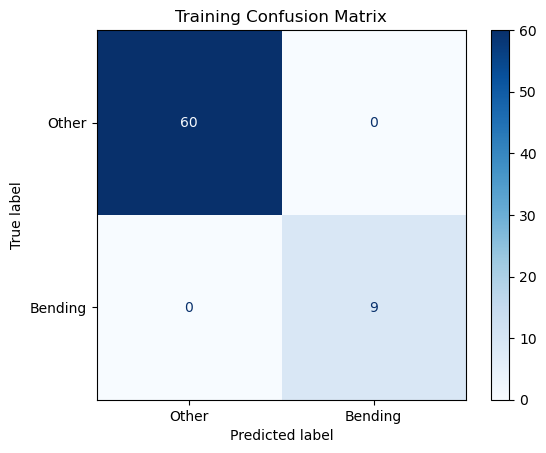

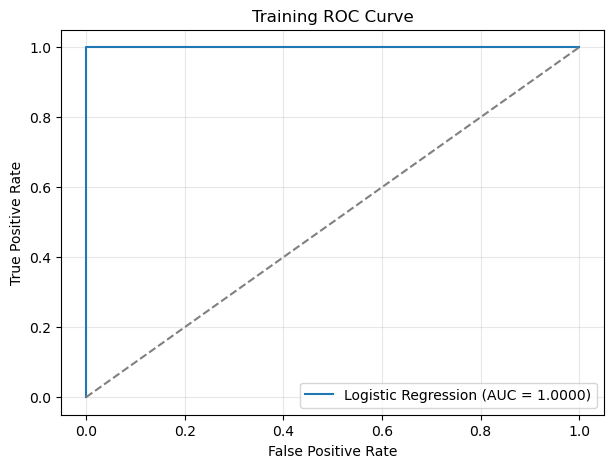

Training AUC: 1.0


In [25]:
import statsmodels.api as sm

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Get the training data for the best value of l
X_best, y_best, feature_names = segment_datasets[best_l]

# Get the fitted scaler and RFE model
scaler = best_model.named_steps["scaler"]
rfe = best_model.named_steps["rfe"]

# Standardize all features
X_scaled = scaler.transform(X_best)

# Keep only the features selected by RFE
selected_mask = rfe.support_
selected_features = np.array(feature_names)[selected_mask]
X_selected = X_scaled[:, selected_mask]

print("Selected features:")
print(selected_features)

# Fit logistic regression with statsmodels
# Add a column for the intercept
X_selected_const = sm.add_constant(X_selected)

logit_model = sm.Logit(y_best, X_selected_const)
logit_result = logit_model.fit(
    method="lbfgs",
    maxiter=5000,
    disp=False
)

# Create a table of coefficients and p-values
parameter_names = ["Intercept"] + list(selected_features)

parameter_results = pd.DataFrame({
    "Parameter": parameter_names,
    "Coefficient": logit_result.params,
    "P-value": logit_result.pvalues
})

display(
    parameter_results.round(6).style.hide(axis="index")
)

# Predictions from the selected best model
train_predictions = best_model.predict(X_best)
train_probabilities = best_model.predict_proba(X_best)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_best, train_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

# ROC curve and AUC
fpr, tpr, thresholds = roc_curve(
    y_best,
    train_probabilities
)

train_auc = roc_auc_score(
    y_best,
    train_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {train_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Training AUC:", round(train_auc, 4))

The training confusion matrix shows that all 60 other activities and all 9 bending activities were classified correctly. Therefore, the training accuracy is 100%.

The training AUC is 1.0, which means that the classifier perfectly separates the two classes on the training data.

However, the p-values are very close to 1 and are not reliable. This is likely caused by complete separation and the small number of bending observations. Therefore, the logistic regression parameter estimates are unstable.

#### v. Test Classifier

Best l: 1
Best p: 19
Number of test instances: 19
Cross-validation accuracy: 0.9857
Test accuracy: 1.0


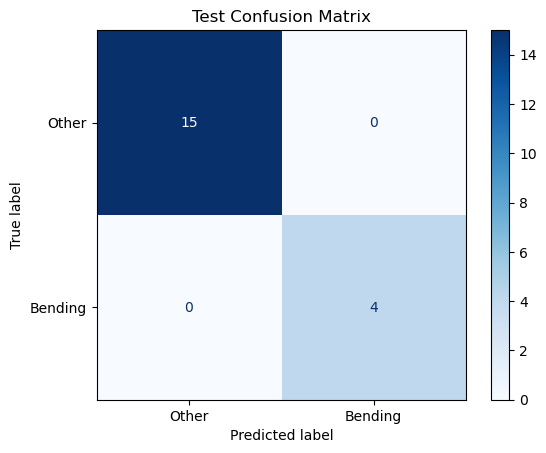

Actual,Predicted
Bending,Bending
Bending,Bending
Bending,Bending
Bending,Bending
Other,Other
Other,Other
Other,Other
Other,Other
Other,Other
Other,Other


In [30]:
from sklearn.metrics import accuracy_score

# Extract test features using the same best l
X_test_best, y_test, test_feature_names = create_segment_features(
    test_files,
    best_l
)

# Make predictions on the test set
test_predictions = best_model.predict(X_test_best)
test_probabilities = best_model.predict_proba(X_test_best)[:, 1]

# Calculate test accuracy
test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

print("Best l:", best_l)
print("Best p:", best_p)
print("Number of test instances:", len(y_test))
print("Cross-validation accuracy:", round(best_cv_accuracy, 4))
print("Test accuracy:", round(test_accuracy, 4))

# Test confusion matrix
test_cm = confusion_matrix(
    y_test,
    test_predictions
)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Test Confusion Matrix")
plt.show()

# Display actual and predicted labels
test_results = pd.DataFrame({
    "Actual": np.where(y_test == 1, "Bending", "Other"),
    "Predicted": np.where(
        test_predictions == 1,
        "Bending",
        "Other"
    )
})

display(test_results.style.hide(axis="index"))

The test set contains 19 instances. The model correctly classified all 15 other activities and all 4 bending activities, so the test accuracy is 1.0.

The test accuracy is slightly higher than the cross-validation accuracy of 0.9857. This result shows that the model performs well on the test data. However, the test set is small, so the 100% accuracy should be interpreted carefully.

#### vi. Separation

Yes, the two classes seem to be well-separated. The model classified every training and test instance correctly, and the training AUC was 1.0. This complete separation can make the logistic regression coefficients and p-values unstable. This may explain why the p-values from the fitted model were not reliable.

#### vii. Imbalance

Original class counts:
0    60
1     9
Name: count, dtype: int64

Balanced class counts:
0    60
1    60
Name: count, dtype: int64


Parameter,Adjusted Coefficient
Intercept,-13.266590
min_series1_segment1,-2.414103
max_series1_segment1,1.640914
mean_series1_segment1,-1.433954
3rd_quart_series1_segment1,-3.472111
max_series2_segment1,-1.935762
min_series3_segment1,-1.504568
max_series3_segment1,1.591966
std_series3_segment1,-1.919410
3rd_quart_series3_segment1,-1.588051


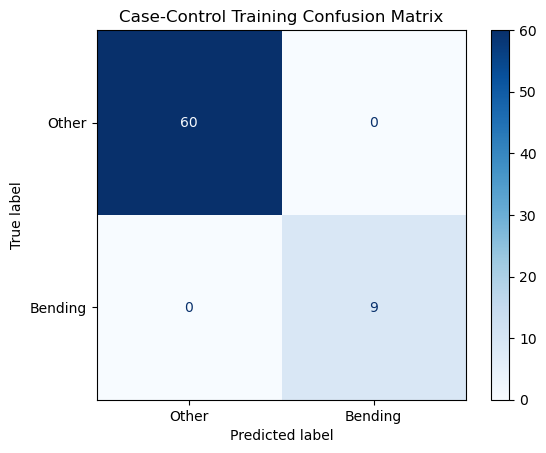

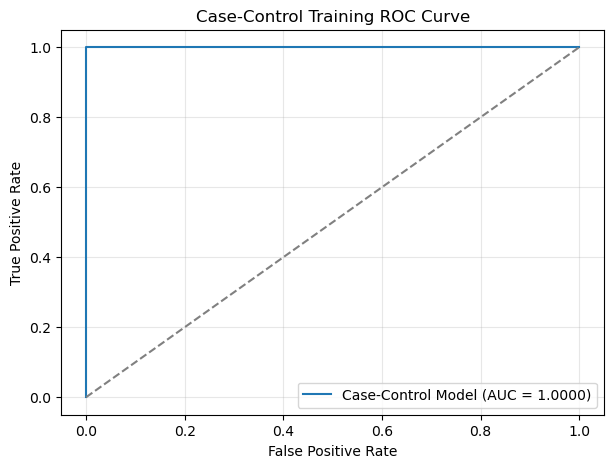

Case-control training AUC: 1.0


In [34]:
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression

# Find the indices of the two classes
other_indices = np.where(y_best == 0)[0]
bending_indices = np.where(y_best == 1)[0]

# Oversample the bending class
bending_indices_resampled = resample(
    bending_indices,
    replace=True,
    n_samples=len(other_indices),
    random_state=42
)

# Create a balanced training set
balanced_indices = np.concatenate([
    other_indices,
    bending_indices_resampled
])

X_balanced = X_selected[balanced_indices]
y_balanced = np.array(y_best)[balanced_indices]

print("Original class counts:")
print(pd.Series(y_best).value_counts())

print("\nBalanced class counts:")
print(pd.Series(y_balanced).value_counts())

# Fit logistic regression using the balanced data
case_control_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=5000
)

case_control_model.fit(
    X_balanced,
    y_balanced
)

# Original and sampled proportions of the bending class
original_probability = np.mean(y_best)
sample_probability = np.mean(y_balanced)

# Adjust the intercept
adjustment = np.log(
    original_probability / (1 - original_probability)
) - np.log(
    sample_probability / (1 - sample_probability)
)

adjusted_intercept = (
    case_control_model.intercept_[0] + adjustment
)

adjusted_coefficients = case_control_model.coef_[0]

# Display the adjusted parameters
adjusted_parameters = pd.DataFrame({
    "Parameter": ["Intercept"] + list(selected_features),
    "Adjusted Coefficient": (
        [adjusted_intercept] +
        list(adjusted_coefficients)
    )
})

display(
    adjusted_parameters.round(6).style.hide(axis="index")
)

# Calculate probabilities using the adjusted parameters
linear_score = (
    adjusted_intercept +
    X_selected @ adjusted_coefficients
)

linear_score = np.clip(linear_score, -500, 500)

adjusted_probabilities = 1 / (
    1 + np.exp(-linear_score)
)

adjusted_predictions = (
    adjusted_probabilities >= 0.5
).astype(int)

# Confusion matrix
adjusted_cm = confusion_matrix(
    y_best,
    adjusted_predictions
)

ConfusionMatrixDisplay(
    confusion_matrix=adjusted_cm,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Case-Control Training Confusion Matrix")
plt.show()

# ROC and AUC
adjusted_auc = roc_auc_score(
    y_best,
    adjusted_probabilities
)

fpr, tpr, thresholds = roc_curve(
    y_best,
    adjusted_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Case-Control Model (AUC = {adjusted_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Training ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Case-control training AUC:", round(adjusted_auc, 4))

The original training data are imbalanced because there are 60 other instances but only 9 bending instances. I used case-control sampling to increase the bending class to 60 instances.

Because sampling changed the class proportion, I adjusted the intercept using the original and sampled class proportions. The other coefficients did not need this adjustment.

The adjusted model correctly classified all 69 original training instances. Its AUC is 1.0. The result is the same as the previous model because the two classes are already completely separated.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [37]:
# Candidate values of C
C_values = np.logspace(-4, 4, 20)

l1_results = []
l1_models = {}
l1_datasets = {}

for l in range(1, 21):

    # Create features for this value of l
    X_l, y_l, feature_names_l = create_segment_features(
        train_files,
        l
    )

    l1_datasets[l] = (
        X_l,
        y_l,
        feature_names_l
    )

    # Standardization and L1 logistic regression
    l1_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        (
            "logistic",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=5000
            )
        )
    ])

    # Choose the best C using stratified 5-fold CV
    l1_grid = GridSearchCV(
        estimator=l1_pipeline,
        param_grid={
            "logistic__C": C_values
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    l1_grid.fit(X_l, y_l)

    best_C_for_l = l1_grid.best_params_[
        "logistic__C"
    ]

    best_accuracy_for_l = l1_grid.best_score_

    # Count the selected features
    coefficients = (
        l1_grid
        .best_estimator_
        .named_steps["logistic"]
        .coef_[0]
    )

    number_of_selected_features = np.sum(
        coefficients != 0
    )

    l1_results.append({
        "l": l,
        "Best C": best_C_for_l,
        "Selected Features":
            number_of_selected_features,
        "CV Accuracy": best_accuracy_for_l
    })

    l1_models[l] = l1_grid.best_estimator_

    print(
        f"Finished l = {l}, "
        f"best C = {best_C_for_l:.6f}, "
        f"selected features = "
        f"{number_of_selected_features}, "
        f"accuracy = {best_accuracy_for_l:.4f}"
    )

# Create the results table
l1_results = pd.DataFrame(l1_results)

display(
    l1_results.round(6).style.hide(axis="index")
)

# Find the best result
best_l1_index = l1_results[
    "CV Accuracy"
].idxmax()

best_l_l1 = int(
    l1_results.loc[best_l1_index, "l"]
)

best_C_l1 = l1_results.loc[
    best_l1_index,
    "Best C"
]

best_l1_accuracy = l1_results.loc[
    best_l1_index,
    "CV Accuracy"
]

best_l1_model = l1_models[best_l_l1]

print("\nBest l:", best_l_l1)
print("Best C:", round(best_C_l1, 6))
print(
    "Best cross-validation accuracy:",
    round(best_l1_accuracy, 4)
)

Finished l = 1, best C = 545.559478, selected features = 14, accuracy = 0.9857
Finished l = 2, best C = 11.288379, selected features = 11, accuracy = 0.9714
Finished l = 3, best C = 0.233572, selected features = 5, accuracy = 0.9571
Finished l = 4, best C = 4.281332, selected features = 12, accuracy = 0.9714
Finished l = 5, best C = 0.615848, selected features = 10, accuracy = 0.9429
Finished l = 6, best C = 545.559478, selected features = 45, accuracy = 0.9571
Finished l = 7, best C = 10000.000000, selected features = 183, accuracy = 0.9429
Finished l = 8, best C = 78.475997, selected features = 29, accuracy = 0.9429
Finished l = 9, best C = 11.288379, selected features = 17, accuracy = 0.9714
Finished l = 10, best C = 29.763514, selected features = 23, accuracy = 0.9714
Finished l = 11, best C = 4.281332, selected features = 11, accuracy = 0.9857
Finished l = 12, best C = 0.615848, selected features = 7, accuracy = 0.9857
Finished l = 13, best C = 1.623777, selected features = 11, ac

l,Best C,Selected Features,CV Accuracy
1,545.559478,14,0.985714
2,11.288379,11,0.971429
3,0.233572,5,0.957143
4,4.281332,12,0.971429
5,0.615848,10,0.942857
6,545.559478,45,0.957143
7,10000.000000,183,0.942857
8,78.475997,29,0.942857
9,11.288379,17,0.971429
10,29.763514,23,0.971429



Best l: 1
Best C: 545.559478
Best cross-validation accuracy: 0.9857


The best L1-penalized logistic regression model uses \(l=1\) and \(C=545.559478\). It selected 14 features and achieved a cross-validation accuracy of 0.9857.

Several values of \(l\) produced the same highest accuracy. I selected \(l=1\) because it was the first best result and it gives the simplest time-series representation.

#### ii. Comparison

Both methods achieved the same cross-validation accuracy of 0.9857. Therefore, neither method performed better based on cross-validation accuracy.

The RFE model selected 19 features, while the L1-penalized model selected 14 features. The L1 model is simpler because it uses fewer features.

L1 regularization is also easier to implement because it selects features during model fitting. The p-value method can be unstable when the classes are completely separated. Therefore, I prefer the L1-penalized model for this dataset.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [41]:
# Multiclass labels for the training data
y_train_multiclass = np.array([
    activity
    for activity, file_path in train_files
])

print("Training class counts:")
print(
    pd.Series(y_train_multiclass)
    .value_counts()
    .sort_index()
)

# Use 4 folds because the smallest class has only 4 samples
multiclass_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Candidate C values
multiclass_C_values = np.logspace(-3, 3, 10)

multiclass_results = []
multiclass_models = {}
multiclass_datasets = {}

for l in range(1, 21):

    # The feature values are the same;
    # only the labels change to seven activity classes
    X_l, binary_y, feature_names_l = (
        create_segment_features(
            train_files,
            l
        )
    )

    multiclass_datasets[l] = (
        X_l,
        y_train_multiclass,
        feature_names_l
    )

    multiclass_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        (
            "logistic",
            LogisticRegression(
                penalty="l1",
                solver="saga",
                max_iter=10000,
                random_state=42
            )
        )
    ])

    multiclass_grid = GridSearchCV(
        estimator=multiclass_pipeline,
        param_grid={
            "logistic__C": multiclass_C_values
        },
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    multiclass_grid.fit(
        X_l,
        y_train_multiclass
    )

    best_C_for_l = multiclass_grid.best_params_[
        "logistic__C"
    ]

    best_accuracy_for_l = (
        multiclass_grid.best_score_
    )

    # A feature is selected if at least one class
    # has a nonzero coefficient
    coefficients = (
        multiclass_grid
        .best_estimator_
        .named_steps["logistic"]
        .coef_
    )

    selected_count = np.sum(
        np.any(coefficients != 0, axis=0)
    )

    multiclass_results.append({
        "l": l,
        "Best C": best_C_for_l,
        "Selected Features": selected_count,
        "CV Accuracy": best_accuracy_for_l
    })

    multiclass_models[l] = (
        multiclass_grid.best_estimator_
    )

    print(
        f"Finished l = {l}, "
        f"best C = {best_C_for_l:.6f}, "
        f"selected features = {selected_count}, "
        f"accuracy = {best_accuracy_for_l:.4f}"
    )

# Display all results
multiclass_results = pd.DataFrame(
    multiclass_results
)

display(
    multiclass_results
    .round(6)
    .style
    .hide(axis="index")
)

# Find the best l and C
best_multiclass_index = multiclass_results[
    "CV Accuracy"
].idxmax()

best_l_multiclass = int(
    multiclass_results.loc[
        best_multiclass_index,
        "l"
    ]
)

best_C_multiclass = multiclass_results.loc[
    best_multiclass_index,
    "Best C"
]

best_multiclass_cv_accuracy = (
    multiclass_results.loc[
        best_multiclass_index,
        "CV Accuracy"
    ]
)

best_multiclass_model = multiclass_models[
    best_l_multiclass
]

print("\nBest l:", best_l_multiclass)
print(
    "Best C:",
    round(best_C_multiclass, 6)
)
print(
    "Best cross-validation accuracy:",
    round(best_multiclass_cv_accuracy, 4)
)

Training class counts:
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64
Finished l = 1, best C = 2.154435, selected features = 21, accuracy = 0.9142
Finished l = 2, best C = 1000.000000, selected features = 83, accuracy = 0.9134
Finished l = 3, best C = 215.443469, selected features = 126, accuracy = 0.8546
Finished l = 4, best C = 215.443469, selected features = 168, accuracy = 0.9126
Finished l = 5, best C = 215.443469, selected features = 210, accuracy = 0.8685
Finished l = 6, best C = 215.443469, selected features = 252, accuracy = 0.8407
Finished l = 7, best C = 2.154435, selected features = 86, accuracy = 0.8121
Finished l = 8, best C = 215.443469, selected features = 336, accuracy = 0.8391
Finished l = 9, best C = 46.415888, selected features = 357, accuracy = 0.8252
Finished l = 10, best C = 215.443469, selected features = 420, accuracy = 0.8252
Finished l = 11, best C = 215.443469, selected featu

l,Best C,Selected Features,CV Accuracy
1,2.154435,21,0.914216
2,1000.000000,83,0.913399
3,215.443469,126,0.854575
4,215.443469,168,0.912582
5,215.443469,210,0.868464
6,215.443469,252,0.840686
7,2.154435,86,0.812092
8,215.443469,336,0.839052
9,46.415888,357,0.825163
10,215.443469,420,0.825163



Best l: 1
Best C: 2.154435
Best cross-validation accuracy: 0.9142


Cross-validation accuracy: 0.9142
Test accuracy: 0.8947
Test error: 0.1053


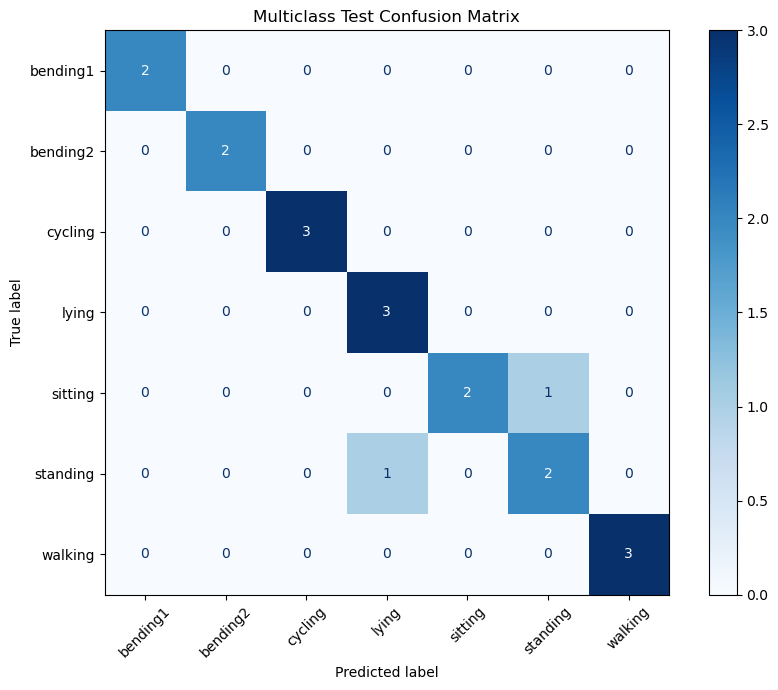

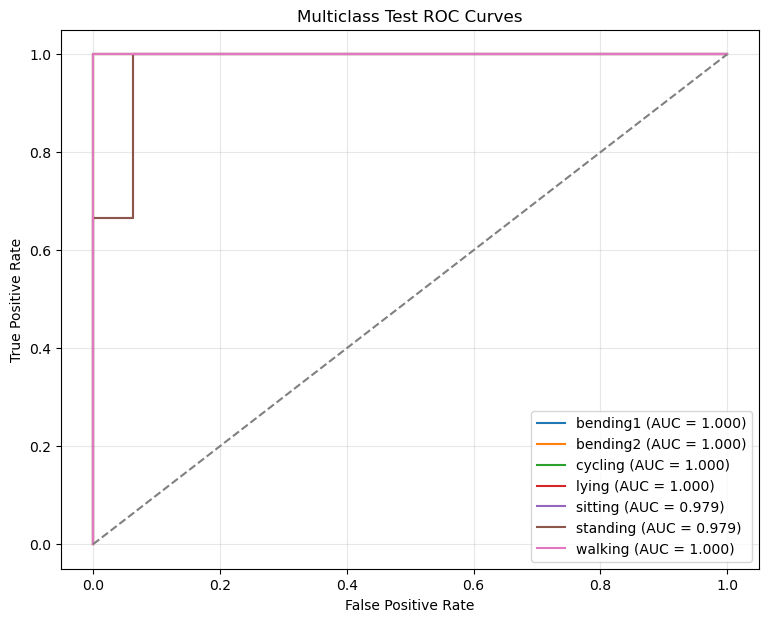

Class,AUC
bending1,1.000000
bending2,1.000000
cycling,1.000000
lying,1.000000
sitting,0.979200
standing,0.979200
walking,1.000000


Macro-average AUC: 0.994


In [43]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Create test features using the same best l
X_test_multiclass, binary_y, test_feature_names = (
    create_segment_features(
        test_files,
        best_l_multiclass
    )
)

# True multiclass test labels
y_test_multiclass = np.array([
    activity
    for activity, file_path in test_files
])

# Test predictions and probabilities
multiclass_predictions = (
    best_multiclass_model.predict(
        X_test_multiclass
    )
)

multiclass_probabilities = (
    best_multiclass_model.predict_proba(
        X_test_multiclass
    )
)

# Accuracy and error
multiclass_test_accuracy = accuracy_score(
    y_test_multiclass,
    multiclass_predictions
)

multiclass_test_error = (
    1 - multiclass_test_accuracy
)

print(
    "Cross-validation accuracy:",
    round(best_multiclass_cv_accuracy, 4)
)

print(
    "Test accuracy:",
    round(multiclass_test_accuracy, 4)
)

print(
    "Test error:",
    round(multiclass_test_error, 4)
)

# Class order used by the model
class_names = (
    best_multiclass_model
    .named_steps["logistic"]
    .classes_
)

# Confusion matrix
multiclass_cm = confusion_matrix(
    y_test_multiclass,
    multiclass_predictions,
    labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=multiclass_cm,
    display_labels=class_names
).plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)

plt.title("Multiclass Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Convert labels to one-versus-rest binary labels
y_test_binary = label_binarize(
    y_test_multiclass,
    classes=class_names
)

# Plot one ROC curve for each class
plt.figure(figsize=(9, 7))

class_auc_values = {}

for i, class_name in enumerate(class_names):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        multiclass_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    class_auc_values[class_name] = class_auc

    plt.plot(
        fpr,
        tpr,
        label=(
            f"{class_name} "
            f"(AUC = {class_auc:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Test ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Macro-average AUC
macro_auc = roc_auc_score(
    y_test_binary,
    multiclass_probabilities,
    average="macro"
)

auc_results = pd.DataFrame({
    "Class": list(class_auc_values.keys()),
    "AUC": list(class_auc_values.values())
})

display(
    auc_results.round(4).style.hide(axis="index")
)

print(
    "Macro-average AUC:",
    round(macro_auc, 4)
)

The best L1-penalized multinomial logistic regression model uses \(l=1\) and \(C=2.154435\). Its cross-validation accuracy is 0.9142.

On the test set, the model correctly classified 17 of the 19 instances. One sitting instance was classified as standing, and one standing instance was classified as lying. The test accuracy is 0.8947, so the test error is 0.1053.

The one-vs-rest ROC curves show strong performance for all seven classes. The macro-average AUC is 0.994. Sitting and standing have slightly lower AUC values of 0.9792, while the other classes have an AUC of 1.0.

#### ii. Naive Bayes

Finished l = 1, Gaussian accuracy = 0.8260, Multinomial accuracy = 0.7533
Finished l = 2, Gaussian accuracy = 0.8260, Multinomial accuracy = 0.7835
Finished l = 3, Gaussian accuracy = 0.6675, Multinomial accuracy = 0.7386
Finished l = 4, Gaussian accuracy = 0.6520, Multinomial accuracy = 0.7108
Finished l = 5, Gaussian accuracy = 0.6078, Multinomial accuracy = 0.7100
Finished l = 6, Gaussian accuracy = 0.5948, Multinomial accuracy = 0.7247
Finished l = 7, Gaussian accuracy = 0.6381, Multinomial accuracy = 0.7377
Finished l = 8, Gaussian accuracy = 0.6503, Multinomial accuracy = 0.6814
Finished l = 9, Gaussian accuracy = 0.6381, Multinomial accuracy = 0.6953
Finished l = 10, Gaussian accuracy = 0.6528, Multinomial accuracy = 0.7092
Finished l = 11, Gaussian accuracy = 0.6217, Multinomial accuracy = 0.6667
Finished l = 12, Gaussian accuracy = 0.6095, Multinomial accuracy = 0.6953
Finished l = 13, Gaussian accuracy = 0.5645, Multinomial accuracy = 0.6814
Finished l = 14, Gaussian accuracy

l,Gaussian CV Accuracy,Multinomial CV Accuracy
1,0.825980,0.753268
2,0.825980,0.783497
3,0.667484,0.738562
4,0.651961,0.710784
5,0.607843,0.709967
6,0.594771,0.724673
7,0.638072,0.737745
8,0.650327,0.681373
9,0.638072,0.695261
10,0.652778,0.709150



Gaussian Naive Bayes
Best l: 2
Best CV accuracy: 0.826

Multinomial Naive Bayes
Best l: 2
Best CV accuracy: 0.7835

Gaussian test accuracy: 0.6316
Gaussian test error: 0.3684

Multinomial test accuracy: 0.7895
Multinomial test error: 0.2105


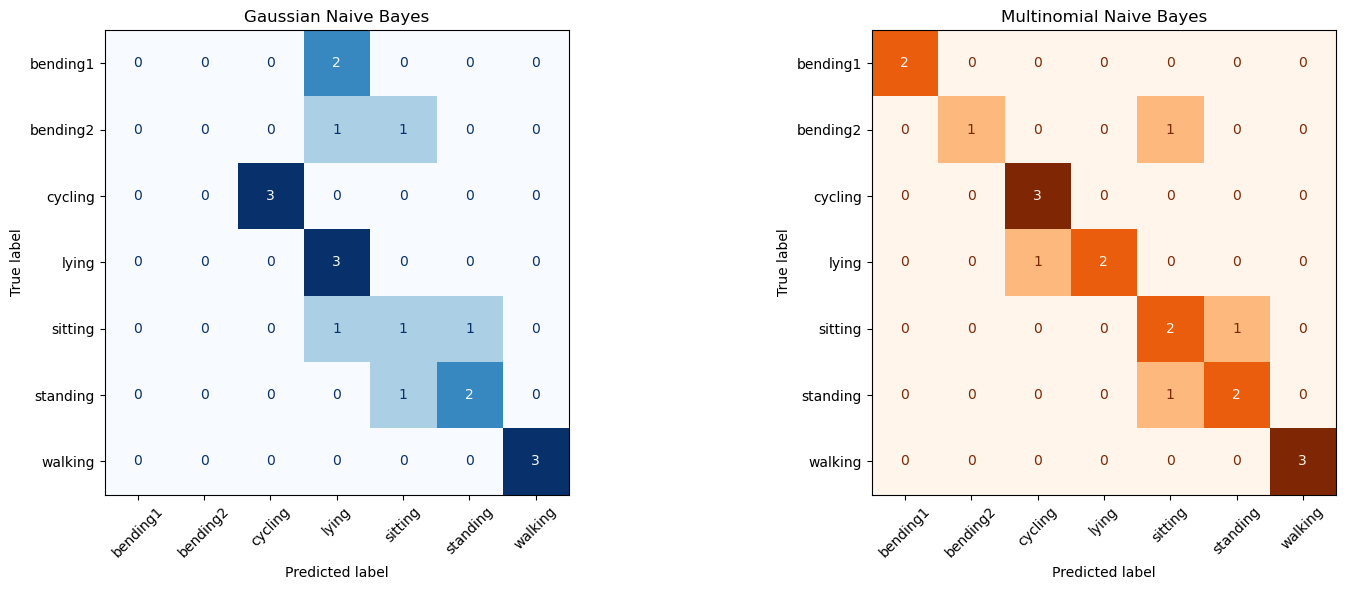

In [46]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

nb_results = []
nb_datasets = {}

for l in range(1, 21):

    X_l, binary_y, feature_names_l = (
        create_segment_features(
            train_files,
            l
        )
    )

    nb_datasets[l] = (
        X_l,
        feature_names_l
    )

    # Gaussian Naive Bayes
    gaussian_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])

    gaussian_scores = cross_val_score(
        gaussian_pipeline,
        X_l,
        y_train_multiclass,
        cv=multiclass_cv,
        scoring="accuracy"
    )

    # Multinomial Naive Bayes
    # MinMaxScaler makes all features nonnegative
    multinomial_pipeline = Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", MultinomialNB())
    ])

    multinomial_scores = cross_val_score(
        multinomial_pipeline,
        X_l,
        y_train_multiclass,
        cv=multiclass_cv,
        scoring="accuracy"
    )

    nb_results.append({
        "l": l,
        "Gaussian CV Accuracy":
            gaussian_scores.mean(),
        "Multinomial CV Accuracy":
            multinomial_scores.mean()
    })

    print(
        f"Finished l = {l}, "
        f"Gaussian accuracy = "
        f"{gaussian_scores.mean():.4f}, "
        f"Multinomial accuracy = "
        f"{multinomial_scores.mean():.4f}"
    )

# Display cross-validation results
nb_results = pd.DataFrame(nb_results)

display(
    nb_results.round(6).style.hide(axis="index")
)

# Find the best l for Gaussian Naive Bayes
best_gaussian_index = nb_results[
    "Gaussian CV Accuracy"
].idxmax()

best_l_gaussian = int(
    nb_results.loc[
        best_gaussian_index,
        "l"
    ]
)

best_gaussian_cv_accuracy = nb_results.loc[
    best_gaussian_index,
    "Gaussian CV Accuracy"
]

# Find the best l for Multinomial Naive Bayes
best_multinomial_index = nb_results[
    "Multinomial CV Accuracy"
].idxmax()

best_l_multinomial = int(
    nb_results.loc[
        best_multinomial_index,
        "l"
    ]
)

best_multinomial_cv_accuracy = nb_results.loc[
    best_multinomial_index,
    "Multinomial CV Accuracy"
]

print("\nGaussian Naive Bayes")
print("Best l:", best_l_gaussian)
print(
    "Best CV accuracy:",
    round(best_gaussian_cv_accuracy, 4)
)

print("\nMultinomial Naive Bayes")
print("Best l:", best_l_multinomial)
print(
    "Best CV accuracy:",
    round(best_multinomial_cv_accuracy, 4)
)

# Get the best training features
X_train_gaussian = nb_datasets[
    best_l_gaussian
][0]

X_train_multinomial = nb_datasets[
    best_l_multinomial
][0]

# Create and fit the final models
best_gaussian_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", GaussianNB())
])

best_multinomial_model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", MultinomialNB())
])

best_gaussian_model.fit(
    X_train_gaussian,
    y_train_multiclass
)

best_multinomial_model.fit(
    X_train_multinomial,
    y_train_multiclass
)

# Create test features using each model's best l
X_test_gaussian, _, _ = create_segment_features(
    test_files,
    best_l_gaussian
)

X_test_multinomial, _, _ = create_segment_features(
    test_files,
    best_l_multinomial
)

# Test predictions
gaussian_predictions = best_gaussian_model.predict(
    X_test_gaussian
)

multinomial_predictions = (
    best_multinomial_model.predict(
        X_test_multinomial
    )
)

# Test accuracy and error
gaussian_test_accuracy = accuracy_score(
    y_test_multiclass,
    gaussian_predictions
)

multinomial_test_accuracy = accuracy_score(
    y_test_multiclass,
    multinomial_predictions
)

gaussian_test_error = 1 - gaussian_test_accuracy
multinomial_test_error = (
    1 - multinomial_test_accuracy
)

print("\nGaussian test accuracy:",
      round(gaussian_test_accuracy, 4))
print("Gaussian test error:",
      round(gaussian_test_error, 4))

print("\nMultinomial test accuracy:",
      round(multinomial_test_accuracy, 4))
print("Multinomial test error:",
      round(multinomial_test_error, 4))

# Confusion matrices
class_names_nb = np.unique(
    y_train_multiclass
)

gaussian_cm = confusion_matrix(
    y_test_multiclass,
    gaussian_predictions,
    labels=class_names_nb
)

multinomial_cm = confusion_matrix(
    y_test_multiclass,
    multinomial_predictions,
    labels=class_names_nb
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

ConfusionMatrixDisplay(
    gaussian_cm,
    display_labels=class_names_nb
).plot(
    cmap="Blues",
    ax=axes[0],
    xticks_rotation=45,
    colorbar=False
)

axes[0].set_title(
    "Gaussian Naive Bayes"
)

ConfusionMatrixDisplay(
    multinomial_cm,
    display_labels=class_names_nb
).plot(
    cmap="Oranges",
    ax=axes[1],
    xticks_rotation=45,
    colorbar=False
)

axes[1].set_title(
    "Multinomial Naive Bayes"
)

plt.tight_layout()
plt.show()

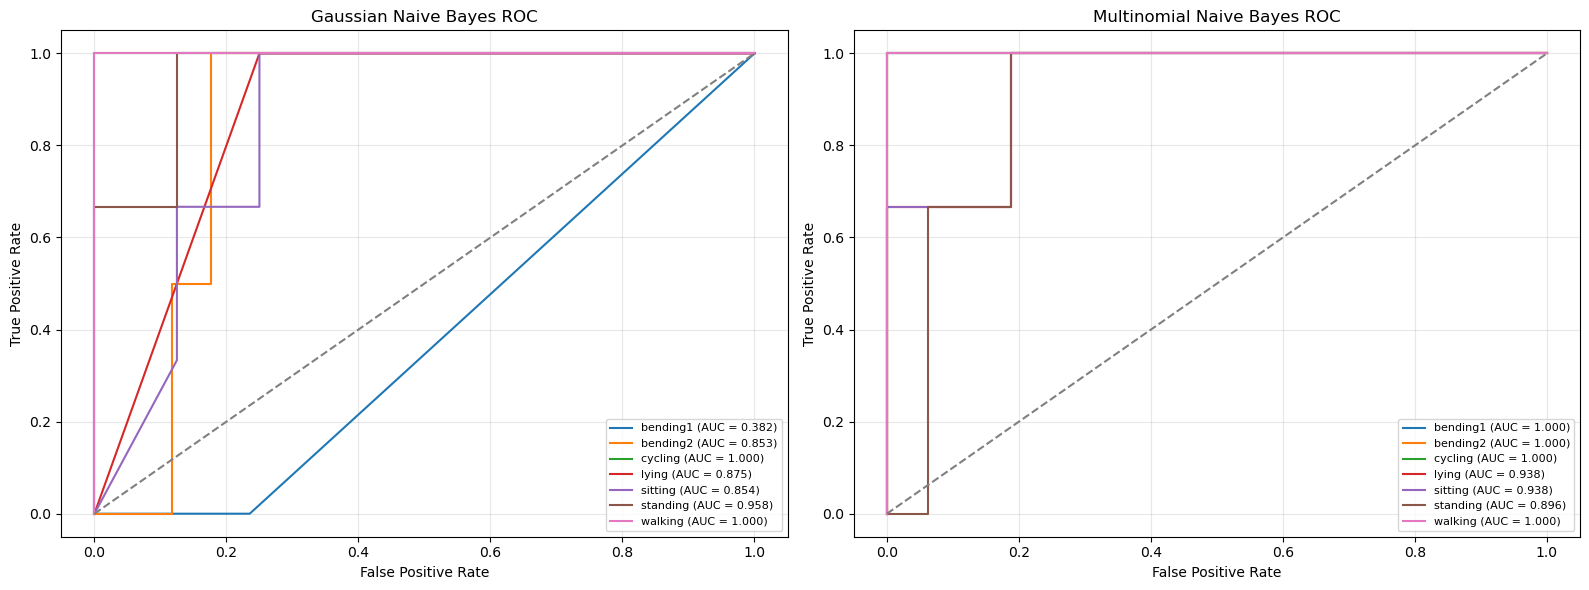

Class,Gaussian AUC,Multinomial AUC
bending1,0.382400,1.000000
bending2,0.852900,1.000000
cycling,1.000000,1.000000
lying,0.875000,0.937500
sitting,0.854200,0.937500
standing,0.958300,0.895800
walking,1.000000,1.000000


Gaussian macro-average AUC: 0.8461
Multinomial macro-average AUC: 0.9673


In [48]:
# Predicted probabilities
gaussian_probabilities = (
    best_gaussian_model.predict_proba(
        X_test_gaussian
    )
)

multinomial_probabilities = (
    best_multinomial_model.predict_proba(
        X_test_multinomial
    )
)

# Convert test labels to one-versus-rest format
y_test_nb_binary = label_binarize(
    y_test_multiclass,
    classes=class_names_nb
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

# Gaussian Naive Bayes ROC curves
gaussian_auc_values = []

for i, class_name in enumerate(class_names_nb):

    fpr, tpr, thresholds = roc_curve(
        y_test_nb_binary[:, i],
        gaussian_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)
    gaussian_auc_values.append(class_auc)

    axes[0].plot(
        fpr,
        tpr,
        label=(
            f"{class_name} "
            f"(AUC = {class_auc:.3f})"
        )
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

axes[0].set_title(
    "Gaussian Naive Bayes ROC"
)
axes[0].set_xlabel(
    "False Positive Rate"
)
axes[0].set_ylabel(
    "True Positive Rate"
)
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Multinomial Naive Bayes ROC curves
multinomial_auc_values = []

for i, class_name in enumerate(class_names_nb):

    fpr, tpr, thresholds = roc_curve(
        y_test_nb_binary[:, i],
        multinomial_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)
    multinomial_auc_values.append(class_auc)

    axes[1].plot(
        fpr,
        tpr,
        label=(
            f"{class_name} "
            f"(AUC = {class_auc:.3f})"
        )
    )

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

axes[1].set_title(
    "Multinomial Naive Bayes ROC"
)
axes[1].set_xlabel(
    "False Positive Rate"
)
axes[1].set_ylabel(
    "True Positive Rate"
)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Macro-average AUC values
gaussian_macro_auc = roc_auc_score(
    y_test_nb_binary,
    gaussian_probabilities,
    average="macro"
)

multinomial_macro_auc = roc_auc_score(
    y_test_nb_binary,
    multinomial_probabilities,
    average="macro"
)

nb_auc_results = pd.DataFrame({
    "Class": class_names_nb,
    "Gaussian AUC": gaussian_auc_values,
    "Multinomial AUC":
        multinomial_auc_values
})

display(
    nb_auc_results
    .round(4)
    .style
    .hide(axis="index")
)

print(
    "Gaussian macro-average AUC:",
    round(gaussian_macro_auc, 4)
)

print(
    "Multinomial macro-average AUC:",
    round(multinomial_macro_auc, 4)
)

Both Naive Bayes models selected \(l=2\). The Gaussian Naive Bayes model had a cross-validation accuracy of 0.8260 and a test error of 0.3684. Its macro-average AUC was 0.8461.

The Multinomial Naive Bayes model had a cross-validation accuracy of 0.7835 and a lower test error of 0.2105. Its macro-average AUC was 0.9673.

Although Gaussian Naive Bayes had a higher cross-validation accuracy, Multinomial Naive Bayes performed better on the test set. It had a lower test error and a higher macro-average AUC.

#### ii. Comparison

The L1-penalized multinomial logistic regression model performed best. Its test error was 0.1053 and its macro-average AUC was 0.994.

Multinomial Naive Bayes was the second-best model, with a test error of 0.2105 and a macro-average AUC of 0.9673. Gaussian Naive Bayes performed worst, with a test error of 0.3684 and a macro-average AUC of 0.8461.

Therefore, L1-penalized multinomial logistic regression is the best method for multi-class classification in this problem.

## 3. ISLR 4.8.3

For class \(k\), assume that

$$
X \mid Y = k \sim N(\mu_k, \sigma_k^2).
$$

The density function for class \(k\) is

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Let \(\pi_k\) be the prior probability of class \(k\). By Bayes' rule, the Bayes classifier assigns \(x\) to the class with the largest value of

$$
\pi_k f_k(x).
$$

Taking the logarithm gives

$$
\log(\pi_k f_k(x))
=
\log(\pi_k)
-\log(\sqrt{2\pi})
-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

The term \(-\log(\sqrt{2\pi})\) is the same for every class, so it can be removed. Therefore, the discriminant function is

$$
\delta_k(x)
=
\log(\pi_k)
-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

This function contains an \(x^2\) term. Since each class can have a different variance, the coefficient

$$
-\frac{1}{2\sigma_k^2}
$$

can be different for each class. Therefore, the \(x^2\) terms do not cancel when two classes are compared.

The decision boundary between classes \(k\) and \(l\) is found by solving

$$
\delta_k(x)=\delta_l(x).
$$

After moving all terms to one side, the equation has the form

$$
Ax^2+Bx+C=0.
$$

Therefore, the Bayes classifier is quadratic, not linear. If all classes had the same variance, the \(x^2\) terms would cancel, and the decision boundary would be linear.

## 4. ISLR 4.8.7

Using Bayes' theorem,

$$
P(\text{Yes} \mid X=4)
=
\frac{P(X=4 \mid \text{Yes})P(\text{Yes})}
{P(X=4 \mid \text{Yes})P(\text{Yes})
+
P(X=4 \mid \text{No})P(\text{No})}.
$$

We are given

$$
P(\text{Yes})=0.8,\qquad P(\text{No})=0.2.
$$

The two classes have variance 36, so their standard deviation is 6. For the
companies that issue dividends, the mean is 10. For the companies that do not
issue dividends, the mean is 0.

Therefore,

$$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{72\pi}}e^{-0.5}
$$

and

$$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{72\pi}}e^{-2/9}.
$$

The common term cancels in Bayes' formula, so

$$
P(\text{Yes} \mid X=4)
=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-2/9}}
\approx 0.7519.
$$

Thus, the probability that the company will issue a dividend is approximately

or about 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9